# Assignment 6 - Transfer learning with ResNet50 (MNIST)
**Offline version** - runs without internet.
Needs `mnist.npz` and the ResNet50 `.h5` weights file in the same folder (see `00_download_once.ipynb`).

In [1]:
%matplotlib inline

import numpy as np
import os
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from IPython.display import display

tf.random.set_seed(42)
np.random.seed(42)

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.22.0-rc0


In [2]:
def load_mnist(path="mnist.npz"):
    for p in (
        path,
        os.path.expanduser("~/.keras/datasets/mnist.npz")
    ):
        if os.path.exists(p):
            with np.load(p, allow_pickle=True) as f:
                return (
                    (f["x_train"], f["y_train"]),
                    (f["x_test"], f["y_test"])
                )

    raise FileNotFoundError(
        "mnist.npz not found. Put it in the notebook folder."
    )


(x_train, y_train), (x_test, y_test) = load_mnist()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


In [3]:
rng = np.random.default_rng(0)

tr = rng.choice(len(x_train), 6000, replace=False)
te = rng.choice(len(x_test), 1500, replace=False)

print("Selected training samples:", len(tr))
print("Selected testing samples:", len(te))

Selected training samples: 6000
Selected testing samples: 1500


In [4]:
def prep(x):

    # Resize grayscale images to 32x32
    x = tf.image.resize(
        x[..., None].astype("float32"),
        (32, 32)
    ).numpy()

    # Convert grayscale to RGB
    x = np.repeat(x, 3, axis=-1)

    # ResNet50 preprocessing
    return preprocess_input(x)


X_tr = prep(x_train[tr])
y_tr = y_train[tr]

X_te = prep(x_test[te])
y_te = y_test[te]

print("Training data shape:", X_tr.shape)
print("Testing data shape:", X_te.shape)

Training data shape: (6000, 32, 32, 3)
Testing data shape: (1500, 32, 32, 3)


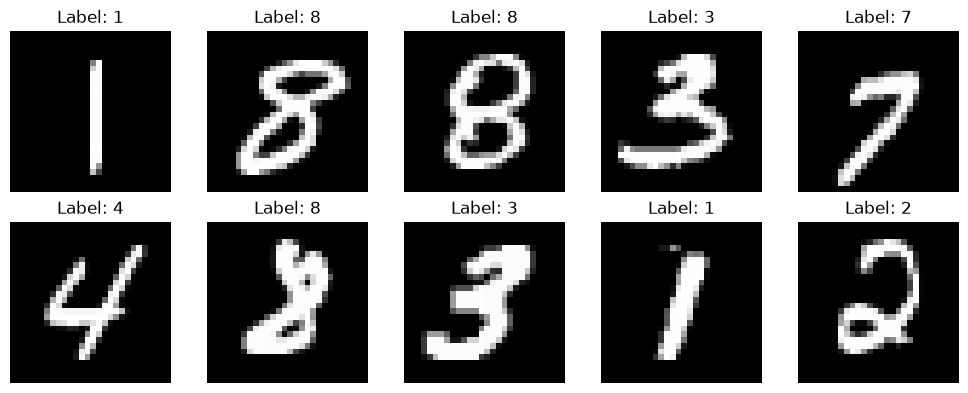

In [5]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[tr[i]], cmap="gray")
    plt.title(f"Label: {y_tr[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
import urllib.request
import os

RESNET_FILE = "resnet50_weights_tf_dim_ordering_tf_kernels_notop.h5"

url = "https://storage.googleapis.com/tensorflow/keras-applications/resnet/" + RESNET_FILE

print("Downloading ResNet50 weights...")

urllib.request.urlretrieve(url, RESNET_FILE)

print("Download completed successfully!")
print("File size:", round(os.path.getsize(RESNET_FILE) / (1024 * 1024), 2), "MB")

Download completed successfully!
File size: 90.38 MB


In [8]:
RESNET_FILE = "resnet50_weights_tf_dim_ordering_tf_kernels_notop.h5"

weights_file = next(
    (
        p for p in (
            RESNET_FILE,
            os.path.expanduser("~/.keras/models/" + RESNET_FILE)
        )
        if os.path.exists(p)
    ),
    None
)

if weights_file is None:
    raise FileNotFoundError(
        RESNET_FILE + " not found. Put it next to this notebook."
    )

base = ResNet50(
    weights=weights_file,
    include_top=False,
    input_shape=(32, 32, 3)
)

print("Base model layers:", len(base.layers))
print("Base model parameters:", f"{base.count_params():,}")

Base model layers: 175
Base model parameters: 23,587,712


In [9]:
base.trainable = False

print("ResNet50 base model frozen successfully!")

ResNet50 base model frozen successfully!


In [10]:
inputs = keras.Input(shape=(32, 32, 3))

x = base(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(256, activation="relu")(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(10, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Classification head added successfully!")

model.summary()

Classification head added successfully!


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 32, 32, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ resnet50 (Functional)                │ (None, 1, 1, 2048)          │      23,587,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         524,544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,114,826 (91.99 MB)

 Trainable params: 527,114 (2.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [11]:
h1 = model.fit(
    X_tr,
    y_tr,
    validation_data=(X_te, y_te),
    epochs=8,
    batch_size=64,
    verbose=2
)

Epoch 1/8
94/94 - 20s - 217ms/step - accuracy: 0.7648 - loss: 0.7719 - val_accuracy: 0.8873 - val_loss: 0.3479
Epoch 2/8
94/94 - 8s - 89ms/step - accuracy: 0.9053 - loss: 0.2911 - val_accuracy: 0.9100 - val_loss: 0.2804
Epoch 3/8
94/94 - 9s - 91ms/step - accuracy: 0.9328 - loss: 0.2138 - val_accuracy: 0.9060 - val_loss: 0.2853
Epoch 4/8
94/94 - 8s - 88ms/step - accuracy: 0.9440 - loss: 0.1739 - val_accuracy: 0.9027 - val_loss: 0.2804
Epoch 5/8
94/94 - 8s - 88ms/step - accuracy: 0.9542 - loss: 0.1423 - val_accuracy: 0.9053 - val_loss: 0.2896
Epoch 6/8
94/94 - 8s - 89ms/step - accuracy: 0.9615 - loss: 0.1190 - val_accuracy: 0.9133 - val_loss: 0.2608
Epoch 7/8
94/94 - 8s - 88ms/step - accuracy: 0.9657 - loss: 0.1044 - val_accuracy: 0.9253 - val_loss: 0.2313
Epoch 8/8
94/94 - 8s - 90ms/step - accuracy: 0.9685 - loss: 0.0912 - val_accuracy: 0.9293 - val_loss: 0.2269


In [12]:
stage1_loss, stage1_acc = model.evaluate(
    X_te,
    y_te,
    verbose=0
)

print(f"Stage-1 test loss: {stage1_loss:.4f}")
print(f"Stage-1 test accuracy: {stage1_acc:.4f}")

Stage-1 test loss: 0.2269
Stage-1 test accuracy: 0.9293


In [13]:
base.trainable = True

for layer in base.layers:
    layer.trainable = (
        layer.name.startswith("conv5")
        and not isinstance(layer, layers.BatchNormalization)
    )

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print(
    "Trainable parameters after fine-tuning:",
    f"{sum(int(np.prod(w.shape)) for w in model.trainable_weights):,}"
)

Trainable parameters after fine-tuning: 15,480,586


In [14]:
h2 = model.fit(
    X_tr,
    y_tr,
    validation_data=(X_te, y_te),
    epochs=6,
    batch_size=64,
    verbose=2
)

Epoch 1/6
94/94 - 70s - 749ms/step - accuracy: 0.9237 - loss: 0.2312 - val_accuracy: 0.9320 - val_loss: 0.2045
Epoch 2/6
94/94 - 57s - 605ms/step - accuracy: 0.9580 - loss: 0.1218 - val_accuracy: 0.9260 - val_loss: 0.2409
Epoch 3/6
94/94 - 57s - 608ms/step - accuracy: 0.9668 - loss: 0.0928 - val_accuracy: 0.9387 - val_loss: 0.2099
Epoch 4/6
94/94 - 57s - 608ms/step - accuracy: 0.9762 - loss: 0.0655 - val_accuracy: 0.9487 - val_loss: 0.1777
Epoch 5/6
94/94 - 60s - 642ms/step - accuracy: 0.9863 - loss: 0.0420 - val_accuracy: 0.9553 - val_loss: 0.1612
Epoch 6/6
94/94 - 71s - 751ms/step - accuracy: 0.9863 - loss: 0.0407 - val_accuracy: 0.9493 - val_loss: 0.1792


In [15]:
final_loss, final_acc = model.evaluate(
    X_te,
    y_te,
    verbose=0
)

print(f"Final test loss: {final_loss:.4f}")
print(f"Final test accuracy: {final_acc:.4f}")

Final test loss: 0.1792
Final test accuracy: 0.9493


In [16]:
loss_all = h1.history["loss"] + h2.history["loss"]

val_loss_all = (
    h1.history["val_loss"] +
    h2.history["val_loss"]
)

acc_all = (
    h1.history["accuracy"] +
    h2.history["accuracy"]
)

val_acc_all = (
    h1.history["val_accuracy"] +
    h2.history["val_accuracy"]
)

n1 = len(h1.history["loss"])

epochs = range(1, len(loss_all) + 1)

print("Total training epochs:", len(loss_all))

Total training epochs: 14


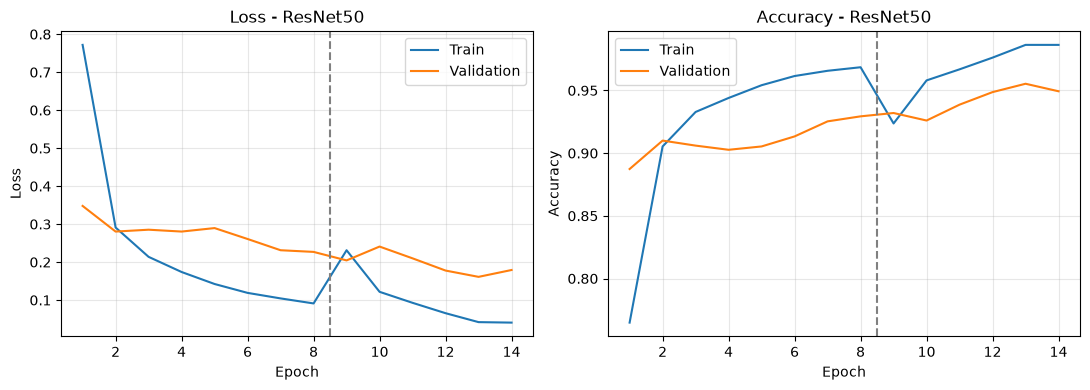

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Loss graph
ax[0].plot(epochs, loss_all, label="Train")
ax[0].plot(epochs, val_loss_all, label="Validation")

ax[0].axvline(
    n1 + 0.5,
    color="gray",
    linestyle="--"
)

ax[0].set_title("Loss - ResNet50")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].legend()
ax[0].grid(alpha=0.3)


# Accuracy graph
ax[1].plot(epochs, acc_all, label="Train")
ax[1].plot(epochs, val_acc_all, label="Validation")

ax[1].axvline(
    n1 + 0.5,
    color="gray",
    linestyle="--"
)

ax[1].set_title("Accuracy - ResNet50")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
fig.savefig(
    "a6_curves.png",
    dpi=150,
    bbox_inches="tight"
)

print("Graph saved successfully!")

Graph saved successfully!


In [19]:
print("\nAssignment 6 completed successfully!")

print("Stage 1: Frozen base training - 8 epochs")
print("Stage 2: Fine-tuning - 6 epochs")

print("Total epochs:", len(loss_all))

print("Stage 1 Accuracy:", stage1_acc)
print("Final Accuracy:", final_acc)

print("Graph saved as: a6_curves.png")


Assignment 6 completed successfully!
Stage 1: Frozen base training - 8 epochs
Stage 2: Fine-tuning - 6 epochs
Total epochs: 14
Stage 1 Accuracy: 0.9293333292007446
Final Accuracy: 0.9493333101272583
Graph saved as: a6_curves.png
